In [2]:
%pip install transformers accelerate scikit-learn torchvision -q

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import os

# Drive mein kya-kya hai check karo
!ls "/content/drive/MyDrive/"

 ai-skin-care
 cafov.jpg
 certificates
'Colab Notebooks'
 completeCV.pdf
 L3NcyCoAjLno9d3T9_gCW7Xki5Y3vNpBmnn_697e37dcd3e77846a78339cf_1769978044942_forage_dataCom_completion_certificate.pdf
 latestTranscript.pdf
 mashhoodCv.pdf
 mashhood_image.jpg
'Mashhood_Intern (10).pdf'
'Mashhood_Intern (11).pdf'
'Mashhood_Intern (12).pdf'
'Mashhood_Intern (13).pdf'
'mashhood-intern (1).pdf'
'Mashhood_Intern (1).pdf'
'mashhood-intern (2).pdf'
'Mashhood_Intern (2).pdf'
'mashhood-intern (3).pdf'
'Mashhood_Intern (3).pdf'
'Mashhood_Intern (4).pdf'
'Mashhood_Intern (5).pdf'
'Mashhood_Intern (6).pdf'
'Mashhood_Intern (7).pdf'
'Mashhood_Intern (8).pdf'
'Mashhood_Intern (9).pdf'
'Mashhood_Intern_CV (1).pdf'
'Mashhood_Intern_CV (2).pdf'
'Mashhood_Intern_CV (3).pdf'
'Mashhood_Intern_CV (4).pdf'
 Mashhood_Intern_CV.pdf
 mashhood-intern.pdf
 Mashhood_Intern.pdf
'mashhood'\''sCV (1) (1).pdf'
'mashhood'\''sCV (1).pdf'
'Mashhood_SE (1).pdf'
 Mashhood_SE.pdf
'Mashhood_Yousaf_Software_Engineer_Resume (1).docx'
'M

In [3]:
import torch
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA: True
GPU: Tesla T4


In [11]:
!ls "/content/drive/MyDrive/ai-skin-care/"

SkinDisease_balanced


In [12]:
!ls "/content/drive/MyDrive/ai-skin-care/SkinDisease_balanced/"

Acne  Eczema  Psoriasis  SkinCancer  Sun_Sunlight_Damage  Unknown_Normal


In [13]:
import os

base = "/content/drive/MyDrive/ai-skin-care/SkinDisease_balanced"
classes = os.listdir(base)
total = 0

for cls in classes:
    path = os.path.join(base, cls)
    if os.path.isdir(path):
        count = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        total += count
        print(f"{cls}: {count} images")

print(f"\nTotal: {total} images")


Unknown_Normal: 300 images
Psoriasis: 300 images
SkinCancer: 300 images
Sun_Sunlight_Damage: 300 images
Acne: 300 images
Eczema: 300 images

Total: 1800 images


In [14]:
import shutil
import os

src = "/content/drive/MyDrive/ai-skin-care/SkinDisease_balanced"
dst = "/content/skin-data/SkinDisease_balanced"

# Purana data ho to delete karo
if os.path.exists("/content/skin-data"):
    shutil.rmtree("/content/skin-data")

# Copy karo
shutil.copytree(src, dst)
print("✅ Copied to:", dst)

# Verify
classes = os.listdir(dst)
for cls in classes:
    count = len(os.listdir(os.path.join(dst, cls)))
    print(f"{cls}: {count} images")

✅ Copied to: /content/skin-data/SkinDisease_balanced
Psoriasis: 300 images
Unknown_Normal: 300 images
Sun_Sunlight_Damage: 300 images
SkinCancer: 300 images
Acne: 300 images
Eczema: 300 images


In [2]:
import torch
import transformers
import sklearn
from PIL import Image

print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("sklearn:", sklearn.__version__)
print("PIL: OK")
print("CUDA:", torch.cuda.is_available())

torch: 2.11.0+cu130
transformers: 5.17.0
sklearn: 1.6.1
PIL: OK
CUDA: True


In [17]:
from datasets import load_dataset

data_path = "/content/skin-data/SkinDisease_balanced"

# ImageFolder se load karo
dataset = load_dataset("imagefolder", data_dir=data_path)

# 80% train, 20% test split karo
dataset = dataset["train"].train_test_split(test_size=0.2, seed=42)

print("Train samples:", len(dataset["train"]))
print("Test samples:", len(dataset["test"]))
print("Labels:", dataset["train"].features["label"].names)

Resolving data files:   0%|          | 0/1799 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Train samples: 1439
Test samples: 360
Labels: ['Acne', 'Eczema', 'Psoriasis', 'SkinCancer', 'Sun_Sunlight_Damage', 'Unknown_Normal']


In [18]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

model_name = "google/vit-base-patch16-224-in21k"
num_labels = 6  # humari 6 classes

print("Loading processor...")
processor = AutoImageProcessor.from_pretrained(model_name)

print("Loading model...")
model = AutoModelForImageClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    ignore_mismatched_sizes=True  # classification head naya hoga
)

print("✅ Model ready")
print(f"Parameters: {model.num_parameters():,}")

Loading processor...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

Loading model...


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Model ready
Parameters: 85,803,270


In [19]:
from torchvision import transforms

# Data augmentation for training
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),  # random crop
    transforms.RandomHorizontalFlip(),                     # left-right flip
    transforms.RandomRotation(15),                         # rotate
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# No augmentation for test
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

print("✅ Transforms ready")

✅ Transforms ready


In [21]:
def preprocess_train(batch):
    images = [img.convert("RGB") for img in batch["image"]]
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

def preprocess_test(batch):
    images = [img.convert("RGB") for img in batch["image"]]
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

# Apply
train_ds = dataset["train"].with_transform(preprocess_train)
test_ds = dataset["test"].with_transform(preprocess_test)

print("✅ Dataset ready for training")
print(f"Train batches will have: pixel_values + labels")

✅ Dataset ready for training
Train batches will have: pixel_values + labels


In [22]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/vision-model",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none",
    remove_unused_columns=False,
    push_to_hub=False,
)

print("✅ Training args ready")

✅ Training args ready


In [23]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    predictions = np.argmax(eval_pred.predictions, axis=1)
    labels = eval_pred.label_ids
    
    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted"
    )
    
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

print("✅ Metrics ready")

✅ Metrics ready


In [24]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics,
)

print("✅ Trainer ready")

✅ Trainer ready


In [25]:
print("🚀 Training shuru...")
print("Time: ~10-15 minutes (Colab T4 GPU)")

train_result = trainer.train()

print("\n✅ Training complete!")
print(f"Training time: {train_result.metrics['train_runtime']:.0f} seconds")
print(f"Final loss: {train_result.metrics['train_loss']:.4f}")

🚀 Training shuru...
Time: ~10-15 minutes (Colab T4 GPU)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.617120,1.502096,0.644444,0.683386,0.644444,0.641931
2,1.179420,1.126258,0.750000,0.753220,0.750000,0.750021
3,0.966391,1.010073,0.800000,0.801142,0.800000,0.800137


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before


✅ Training complete!
Training time: 221 seconds
Final loss: 1.3254


In [26]:
# Test set pe final evaluation
results = trainer.evaluate()

print("\n📊 Final Test Results:")
print(f"Accuracy:  {results['eval_accuracy']:.2%}")
print(f"Precision: {results['eval_precision']:.2%}")
print(f"Recall:    {results['eval_recall']:.2%}")
print(f"F1 Score:  {results['eval_f1']:.2%}")
print(f"Loss:      {results['eval_loss']:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.966391,1.010073,3,0.800000,0.801142,0.800000,0.800137



📊 Final Test Results:
Accuracy:  80.00%
Precision: 80.11%
Recall:    80.00%
F1 Score:  80.01%
Loss:      1.0101


In [27]:
# Colab local mein save karo
save_path = "/content/vision-model-final"
trainer.save_model(save_path)
processor.save_pretrained(save_path)

print("✅ Model saved to:", save_path)

import os
files = os.listdir(save_path)
print("\nFiles:")
for f in files:
    size = os.path.getsize(os.path.join(save_path, f)) / (1024*1024)
    print(f"  {f}: {size:.1f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model saved to: /content/vision-model-final

Files:
  training_args.bin: 0.0 MB
  model.safetensors: 327.3 MB
  config.json: 0.0 MB
  preprocessor_config.json: 0.0 MB


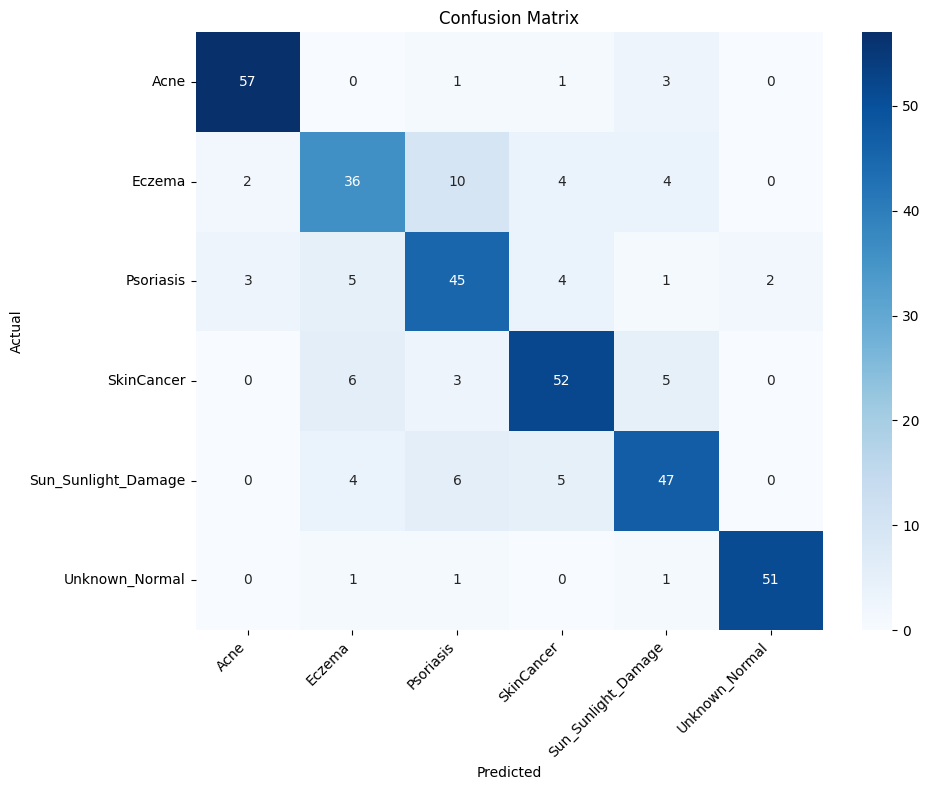

In [28]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predictions lo
predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=1)
labels = predictions.label_ids

# Confusion matrix
cm = confusion_matrix(labels, preds)
class_names = dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
import shutil
import os

# Drive pe folder banao
drive_save = "/content/drive/MyDrive/ai-skin-care/vision-model-final"

# Agar pehle se hai to delete karo
if os.path.exists(drive_save):
    shutil.rmtree(drive_save)

# Copy karo
shutil.copytree("/content/vision-model-final", drive_save)

print("✅ Model saved to Drive:", drive_save)
print("\nFiles:")
for f in os.listdir(drive_save):
    size = os.path.getsize(os.path.join(drive_save, f)) / (1024*1024)
    print(f"  {f}: {size:.1f} MB")

✅ Model saved to Drive: /content/drive/MyDrive/ai-skin-care/vision-model-final

Files:
  training_args.bin: 0.0 MB
  model.safetensors: 327.3 MB
  config.json: 0.0 MB
  preprocessor_config.json: 0.0 MB


In [ ]:
def preprocess_train(batch):
    images = [img.convert("RGB") for img in batch["image"]]
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

def preprocess_test(batch):
    images = [img.convert("RGB") for img in batch["image"]]
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

# Apply
train_ds = dataset["train"].with_transform(preprocess_train)
test_ds = dataset["test"].with_transform(preprocess_test)

print("✅ Dataset ready for training")
print(f"Train batches will have: pixel_values + labels")

✅ Dataset ready for training
Train batches will have: pixel_values + labels


In [ ]:
# to see, what's including in test data 

# Test set ke classes dekho
from collections import Counter

test_labels = dataset["test"]["label"]
class_names = dataset["train"].features["label"].names

counter = Counter(test_labels)
print("Test set distribution:")
for idx, count in sorted(counter.items()):
    print(f"  {class_names[idx]}: {count} images")

print(f"\nTotal test: {len(dataset['test'])}")
print(f"Total train: {len(dataset['train'])}")